# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [42]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [43]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [44]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [45]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [69]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])
print(data[['sex_label', 'sex']])

     sex_label     sex
0            1    male
1            0  female
2            0  female
3            0  female
4            1    male
..         ...     ...
886          1    male
887          0  female
888          0  female
889          1    male
890          1    male

[891 rows x 2 columns]


In [73]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')
print(data[['embarked']].head())
print("\nConjunto de datos one-hot codificado:")   
print(onehot_encoder)

  embarked
0        S
1        C
2        S
3        S
4        S

Conjunto de datos one-hot codificado:
     embarked_C  embarked_Q  embarked_S
0         False       False        True
1          True       False       False
2         False       False        True
3         False       False        True
4         False       False        True
..          ...         ...         ...
886       False       False        True
887       False       False        True
888       False       False        True
889        True       False       False
890       False        True       False

[891 rows x 3 columns]


In [48]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [74]:
"""primero imprimi los copnjuntos de datos codificados para poder apreciar las diferencias entre los dos tipos de codificación.

Las principales diferencias que puede observarse entre LabelEncoder y OneHotEncoder son:
1. LabelEncoder asigna un valor numérico a cada categoría, mientras que OneHotEncoder crea una columna para cada categoría.
"""



'primero imprimi los copnjuntos de datos codificados para poder apreciar las diferencias entre los dos tipos de codificación.\n\nLas principales diferencias que puede observarse entre LabelEncoder y OneHotEncoder son:\n1. LabelEncoder asigna un valor numérico a cada categoría, mientras que OneHotEncoder crea una columna para cada categoría.\n'

### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

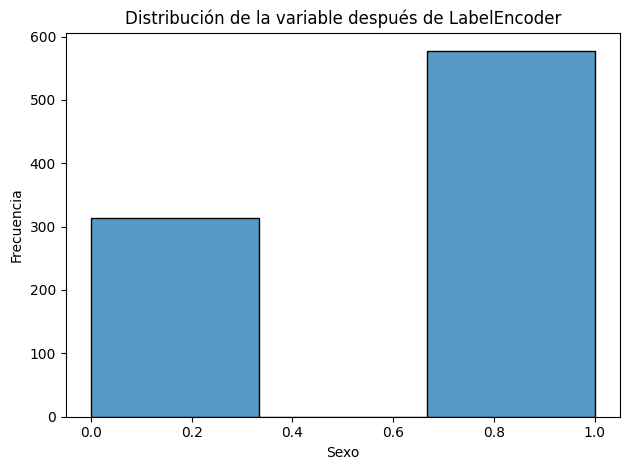

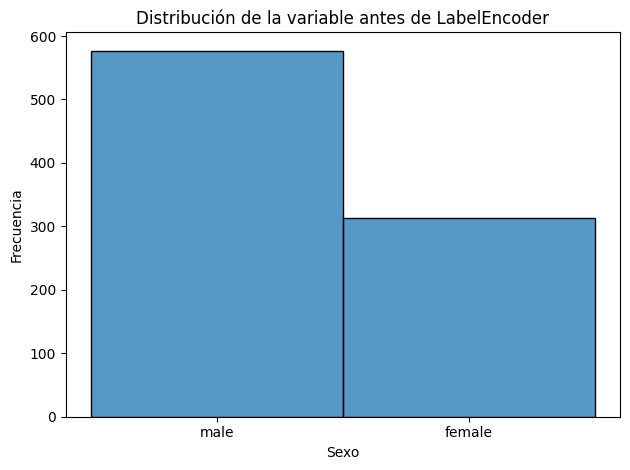

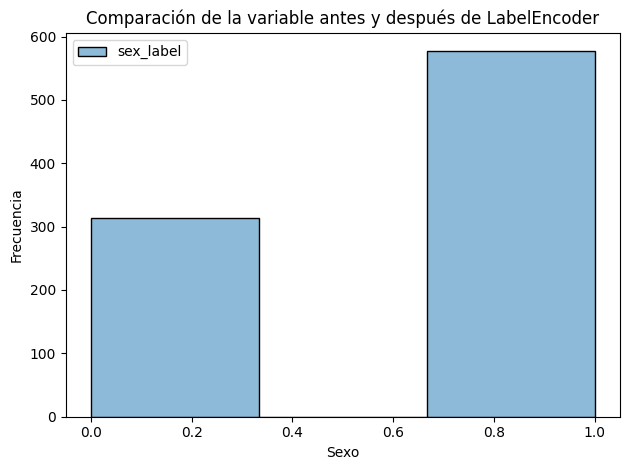

In [87]:
sns.histplot(data['sex_label'], bins=3, kde=False)
plt.title('Distribución de la variable después de LabelEncoder')
plt.xlabel('Sexo')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

sns.histplot(data['sex'], bins=3, kde=False)    
plt.title('Distribución de la variable antes de LabelEncoder')
plt.xlabel('Sexo')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

diferencia = pd.DataFrame({'sex': data['sex'], 'sex_label': data['sex_label']})
sns.histplot(data=diferencia, bins=3, kde=False)
plt.title('Comparación de la variable antes y después de LabelEncoder')
plt.xlabel('Sexo')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [79]:
Onehot_class = pd.get_dummies(data['class'], prefix='class')

print(data[['class']].head())
print("\nConjunto de datos one-hot codificado para la variable 'class':")
print(Onehot_class)

   class
0  Third
1  First
2  Third
3  First
4  Third

Conjunto de datos one-hot codificado para la variable 'class':
     class_First  class_Second  class_Third
0          False         False         True
1           True         False        False
2          False         False         True
3           True         False        False
4          False         False         True
..           ...           ...          ...
886        False          True        False
887         True         False        False
888        False         False         True
889         True         False        False
890        False         False         True

[891 rows x 3 columns]


### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [ ]:
"""Dependería de que estoy buscando que dicho modelo aprenda, de primera instancia y sin mucha experiencia, 
puedo decir que me parece más versatíl OneHot, ya que no asigna un valor numerico a cada categoría y por enede no da un orden 
especifico, que pueda afectar el aprendizaje del modelo.
"""